# Neural bandit models aligned to the published code

Published source: [Eckstein et al., Nature Human Behaviour (2026)](https://doi.org/10.1038/s41562-025-02324-0), supplied as `s41562-025-02324-0-2.pdf`. Code pinned to [`baf38da49fd1c1537affbc3745e961bbf0ae547d`](https://github.com/google-deepmind/hybrid_rnns_reward_learning/tree/baf38da49fd1c1537affbc3745e961bbf0ae547d). The article and code differ in several details; the distinctions below are deliberate. Restart the kernel before using the updated modules. Previous source/notebook versions are archived under `results/model_implementation_archive/pre_release_alignment_*`; existing result directories are preserved.

This notebook implements the four main architectures with the released **BiRNN/RNN** computations: RL-ANN, Context-ANN, Memory-ANN and Vanilla RNN. Models predict choices using only past observations. It retains the original Q-learning simulation as a labelled baseline, then provides neural simulation, synthetic fitting, audited cohort loading, released-protocol population fitting, saved-weight inspection and controlled reward probes.

The update corrects the earlier text-only reconstruction: RL-ANN/Context-ANN now learn **increments added to decayed values**; Memory-ANN **replaces** the chosen value without decaying it; hybrids fit a common initial action-kernel value; Memory retains the code's zero input slot; initialization and AdamW/loss conventions follow the release. All four four-arm parameter counts now match the paper. Refit these models after restarting the kernel; weights from the earlier architecture are not compatible.

RL-ANN and Context-ANN use feedforward tanh MLPs within each update, with recurrence through Q/c. Memory-ANN uses independent recurrent hidden states for rewards and actions. Vanilla RNN has a joint recurrent state. These are tanh networks, not LSTMs/GRUs. The released example's bare defaults do not define every paper model: this notebook sets the model-specific recurrence flags and unit channel weights explicitly.

## Original Q-learning simulation baseline
The original example below uses learning_rate, beta and alpha (stickiness). It is retained as a behavioral baseline and is not a neural model. Neural plots label learned channel contributions and logits rather than assuming they are calibrated reward expectations.


In [6]:
# Resolve imports when the notebook kernel starts in this notebook's directory.
from pathlib import Path
import sys
rnn_repo_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p / "src/agents/neural_bandit.py").exists())
if str(rnn_repo_root) not in sys.path:
    sys.path.insert(0, str(rnn_repo_root))
from src.agents.mouse_agents import *
from src.tasks.drifting_bandit import *
import numpy as np
import matplotlib.pyplot as plt

In [7]:
# Define the parameters and structure of the task
num_trials = 1000
arms = [0, 1, 4]
num_arms = 3
drift_rate = 0.1
swap_mode = "most_chosen"  # "random" or "most_chosen" (among nonzero arms)

# Define the parameters for the mouse
learning_rate = 0.05
alpha = 0.25
beta = 2

bandit_task = DriftingBanditTask(arms, drift_rate=drift_rate, swap_mode=swap_mode)
mouse = QLearningMouse(num_arms, learning_rate, beta, alpha)
actions, rewards, q_values = bandit_task.simulate(mouse, num_trials)
# Available reward for each arm on every trial (trials x arms).
trial_groups = np.asarray(bandit_task.arm_history)


In [8]:
from pathlib import Path


def plot_summary_q_actions_figure(
    trial_groups, num_trials, snippet, actions, rewards, q_values, save_path=None
):
    """Plot available rewards/choices and post-update Q-values for one session.

    trial_groups and q_values have shape (num_trials, num_arms).
    actions contains zero-based arm indices. snippet selects the first trials;
    use None for the full session. save_path is a base path for PNG/PDF files.
    """
    magnitudes = np.asarray(trial_groups, dtype=float)
    q = np.asarray(q_values, dtype=float)
    choices = np.asarray(actions)
    received = np.asarray(rewards, dtype=float)
    if not isinstance(num_trials, (int, np.integer)) or num_trials <= 0:
        raise ValueError("num_trials must be a positive integer.")
    if magnitudes.ndim != 2 or magnitudes.shape[0] != num_trials or magnitudes.shape[1] == 0:
        raise ValueError("trial_groups must have shape (num_trials, num_arms).")
    if q.shape != magnitudes.shape:
        raise ValueError("q_values must have the same shape as trial_groups.")
    if choices.shape != (num_trials,) or received.shape != (num_trials,):
        raise ValueError("actions and rewards must each contain num_trials entries.")
    if not np.issubdtype(choices.dtype, np.integer) or np.any(
        (choices < 0) | (choices >= magnitudes.shape[1])
    ):
        raise ValueError("actions must contain valid zero-based arm indices.")
    if not np.allclose(received, magnitudes[np.arange(num_trials), choices]):
        raise ValueError("rewards do not match the chosen arms in trial_groups.")
    if snippet is not None and (
        not isinstance(snippet, (int, np.integer)) or snippet <= 0
    ):
        raise ValueError("snippet must be a positive integer or None.")

    n = num_trials if snippet is None else min(snippet, num_trials)
    trials = np.arange(1, n + 1)
    colors = ["#A6CEE3", "#FDBF6F", "#B2DF8A"]
    fig, (ax_rewards, ax_q) = plt.subplots(
        2, 1, figsize=(14, 7), sharex=True, layout="constrained"
    )
    for arm in range(magnitudes.shape[1]):
        color = colors[arm % len(colors)]
        ax_rewards.step(trials, magnitudes[:n, arm], where="mid",
                        color=color, linewidth=2.5, label=f"Arm {arm + 1}")
        ax_q.plot(trials, q[:n, arm], color=color, linewidth=2,
                  label=f"Arm {arm + 1}")
    ax_rewards.scatter(trials, received[:n], color="black", s=25,
                       zorder=5, label="Choice / received reward")

    # Mark changes in which arm is zero, between the affected trials.
    zero_changed = np.any(
        (magnitudes[1:n] == 0) != (magnitudes[:n - 1] == 0), axis=1
    )
    for j, boundary in enumerate(np.flatnonzero(zero_changed) + 1.5):
        for ax in (ax_rewards, ax_q):
            ax.axvline(boundary, color="0.55", linestyle="--", alpha=0.6,
                       linewidth=1, label="Zero-arm swap" if j == 0 else None)

    ax_rewards.set_title(f"Model session — first {n} of {num_trials} trials")
    ax_rewards.set_ylabel("Reward magnitude")
    ax_rewards.set_yticks([0, 1, 2, 3, 4])
    ax_q.set_ylabel("Q-value (after update)")
    ax_q.set_xlabel("Trial")
    ax_q.set_xlim(0.5, n + 0.5)
    for ax in (ax_rewards, ax_q):
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(loc="upper left", ncol=5, fontsize=9)
    if save_path is not None:
        base = Path(save_path)
        base.parent.mkdir(parents=True, exist_ok=True)
        for extension in ("png", "pdf"):
            fig.savefig(f"{base}.{extension}", dpi=300, bbox_inches="tight")
    plt.show()
    return fig, (ax_rewards, ax_q)


## Dependencies, initialization and source pin

Models live in `src/agents/neural_bandit.py` and use the shared fitter in `src/agents/paper_rl_fitting.py`. Install `requirements-paper-rl.txt` in the notebook kernel. Upstream numerical parity tests additionally use `requirements-reference-tests.txt`; Haiku is not needed for ordinary fitting.

Weights now use the **Haiku Linear distribution**: truncated normal (±2 standard deviations) divided by sqrt(fan_in), with zero biases. Hybrid q_init/c_init are independent N(1,1) scalar draws; raw forgetting is N(0,1), transformed by sigmoid. Initial hidden states are zero. Our functional implementation uses float64 and its own JAX key allocation, so an identical integer seed is not expected to reproduce Haiku's exact initial arrays. Numerical equivalence is tested at matched arrays.

Full sessions are differentiated without truncating history. Padding is masked out of loss and state updates. There is no added gradient clipping, dropout or learning-rate schedule. Learning is behavioral cloning of observed actions; free-running simulation below serves a different purpose.


In [9]:
# Independent setup for the new neural sections.
from pathlib import Path
import sys
import random
import itertools
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
rnn_repo_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p / "src/agents/neural_bandit.py").exists())
if str(rnn_repo_root) not in sys.path:
    sys.path.insert(0, str(rnn_repo_root))
from src.agents.paper_rl_fitting import dependencies, split_by_mouse, split_by_problem, run_paper_sweep, run_problem_sweep, FULL_GRID
from src.agents.neural_bandit import (
    NEURAL_MODELS, DISPLAY_NAMES, PAPER_CHOSEN, initialize_parameters,
    parameter_summary, trace_sequence, probe_reward_module, NeuralBanditMouse,
)
from src.agents.mouse_agents import QLearningMouse
from src.tasks.drifting_bandit import DriftingBanditTask
jax, jnp, optax = dependencies()


## Released equations and state timing

Use K arms (3 here), H hidden units and one-hot action e(a_t). At trial t, predict from state accumulated through t−1, then observe a_t,r_t and advance state. The released loss scores trials 2…T: the first observation initializes the history but its choice is not scored. Simulation can still draw the first action from initial logits.

Each reward MLP returns a scalar U_t; each action MLP returns a K-vector c. Both use tanh hidden activation and unrestricted linear readout. They have separate parameters. Let D(Q)=(1−f)Q+f Q_init, with learned sigmoid f. Hybrids start with Q=Q_init·1 and c=c_init·1 (both learned scalars), zero hidden states, and choose from softmax(Q+c). Beta and both channel weights are fixed at one.

### RL-ANN: learned increments
\[
U_t=F_r([Q_t(a_t),r_t]),\qquad
Q_{t+1}=D(Q_t)+e(a_t)U_t,\qquad c_{t+1}=G_a(e(a_t)).
\]
The scalar reward output is an **increment**, added to the chosen entry after all values have decayed. It is not a replacement value and need not be a literal prediction error. The action network replaces all entries of c using only the most recent action; earlier c or hidden state is not fed back.

### Context-ANN: output recurrence
\[
U_t=F_r([Q_t(a_t),r_t,Q_t]),\qquad
Q_{t+1}=D(Q_t)+e(a_t)U_t,\qquad
c_{t+1}=G_a([e(a_t),c_t]).
\]
Inputs use pre-update Q/c. Q context consists of learned values, not true unchosen rewards. Learned c_init affects the first action-module update here.

### Memory-ANN: hidden recurrence and replacement
\[
s^r_{t+1}=\tanh(W^r_1[0,r_t,s^r_t]+b^r_1),\qquad
U_t=(w^r_2)^\top s^r_{t+1}+b^r_2,
\]
\[
Q_{t+1}(a_t)=U_t,\qquad Q_{t+1}(j\ne a_t)=D(Q_t)(j),
\]
\[
s^a_{t+1}=\tanh(W^a_1[e(a_t),s^a_t]+b^a_1),\qquad
c_{t+1}=W^a_2s^a_{t+1}+b^a_2.
\]
Only unchosen Q entries retain the decay; the chosen entry is overwritten by U_t. The explicit zero input slot mirrors `zero_values=True` in BiRNN: it replaces the chosen-Q input numerically but its H weights still exist. Those weights have zero data gradient and undergo weight decay. A single global reward hidden state receives rewards and no action identities; a separate global action hidden state receives choices and no rewards. The external chosen-arm write routes reward output to Q. There are no per-arm hidden-state banks or extra action-kernel decay.

### Vanilla RNN: joint memory
\[
s_{t+1}=\tanh(W_1[e(a_t),r_t,s_t]+b_1),\qquad
h_t=W_2s_t+b_2,\qquad p_t=\operatorname{softmax}(h_t).
\]
The released RNN explicitly concatenates previous hidden state, resolving the omitted recurrence in the printed equation. Hidden state starts at zero. No Q/c, fitted initial hidden state, explicit forgetting or beta parameter is present. Its learned output bias can affect first-choice simulation, but that choice is excluded from released fitting.

Q/c are contributions to logits, not calibrated expected reward values. Individual network weights are not behavioral learning-rate parameters. Hidden-state permutations and other equivalent representations prevent straightforward weight-by-weight recovery; inspect predictive behavior and controlled network functions.


## Code reconciliation and parameter counts

### Neural models

Use one-hot actions for all models. Hybrids have independent reward/action tanh networks with linear readouts, additive logits Q+c, beta=1 and channel weights both fixed to 1. Fit **three** scalar parameters in each hybrid: Q_init, c_init and a sigmoid-transformed forgetting rate. Hidden states start at zero. Initial Q and c are common scalars broadcast across arms.

Let D(Q)=(1-f)Q+f Q_init, and U be the reward network's scalar output. Inputs refer to state before the observation's update.

| Model | Reward input | Chosen Q after observation | Unchosen Q | Action-network input |
|---|---|---|---|---|
| RL-ANN | [Q(chosen), reward] | D(Q)(chosen)+U | D(Q) | one-hot action |
| Context-ANN | [Q(chosen), reward, Q vector] | D(Q)(chosen)+U | D(Q) | [one-hot action, c vector] |
| Memory-ANN | [0, reward, previous reward hidden state] | U | D(Q) | [one-hot action, previous action hidden state] |

The zero Memory-ANN input is a real input slot with H weights. Those weights have zero data gradient, but are included in parameter counts and AdamW decay. The action network replaces the entire c vector. No additional action-kernel decay is applied. The reward and action hidden states are global per session, not per arm. Reward memory does not directly observe actions; the external chosen-arm write routes its output to Q. For RL-ANN and Memory-ANN the scalar initial c does not affect later action-network outputs; it remains part of the released parameterization.

Vanilla RNN uses `[one-hot action, reward, previous hidden state]`, tanh hidden activation and a linear K-logit readout. No separate Q/c, forgetting, or beta parameter is fitted. Its output bias can encode first-choice arm preferences, but first choices are excluded from the released training objective.

These definitions follow [BiRNN](https://github.com/google-deepmind/hybrid_rnns_reward_learning/blob/baf38da49fd1c1537affbc3745e961bbf0ae547d/hybrid_rnns_reward_learning/bi_rnn.py) and [RNN](https://github.com/google-deepmind/hybrid_rnns_reward_learning/blob/baf38da49fd1c1537affbc3745e961bbf0ae547d/hybrid_rnns_reward_learning/rnn.py). The winning Memory preset is given in `train_models.ipynb`; RL-ANN/Context-ANN are configured via `s=False` with `o=False/True`, `zero_values=False`, fitted forgetting/Q_init/c_init and unit channel weights. Bare `rnn_config.py` defaults are an example configuration, not the final paper presets.

For K arms and H hidden units, counts are RL-ANN `H(2K+5)+K+4`; Context-ANN `H(4K+5)+K+4`; Memory-ANN `2H²+(2K+5)H+K+4`; Vanilla `H²+(2K+2)H+K`. At the paper's K=4 and H=16/64/32/64 these are **216/1352/2472/4740**, now matching the reported counts exactly.


The previous approximate counts (215/1,351/2,439) arose from omitted c_init and Memory's zero input slot; those discrepancies are resolved by the released source. Scalar c_init is fitted by the source even when it has no effect on later outputs (RL-ANN and Memory-ANN). Parameter count is therefore not identical to the number of behaviorally identifiable quantities.

The release and manuscript still differ in update/loss details. Here **neural computation follows the released code**, while subject-disjoint splitting follows the published experiment; the table in the fitting section records these choices. No claim is made that the public example exactly reproduces every reported experiment.


In [10]:
# Network shapes/counts for the mouse task and the paper's four-arm task.
rnn_count_rows = []
for model in NEURAL_MODELS:
    width = PAPER_CHOSEN[model]["hidden_units"]
    for n_arms in [3, 4]:
        params = initialize_parameters(jax.random.PRNGKey(42), model, width, n_arms)
        rnn_count_rows.append(dict(model=DISPLAY_NAMES[model], num_arms=n_arms,
                                   **parameter_summary(params, model)))
display(pd.DataFrame(rnn_count_rows))
display(pd.DataFrame([
    dict(model=DISPLAY_NAMES[model], **settings, optimizer_learning_rate=1e-4, weight_decay=1e-5)
    for model, settings in PAPER_CHOSEN.items()
]))


,model,num_arms,hidden_units,n_parameters,forgetting,q_init,c_init
0,RL-ANN,3,16,183,0.108345,0.865926,1.204018
1,RL-ANN,4,16,216,0.108345,0.865926,1.204018
2,Context-ANN,3,64,1095,0.108345,0.865926,1.204018
3,Context-ANN,4,64,1352,0.108345,0.865926,1.204018
4,Memory-ANN,3,32,2407,0.108345,0.865926,1.204018
5,Memory-ANN,4,32,2472,0.108345,0.865926,1.204018
6,Vanilla RNN,3,64,4611,NaN,NaN,NaN
7,Vanilla RNN,4,64,4740,NaN,NaN,NaN


,model,hidden_units,batch_size,max_steps,optimizer_learning_rate,weight_decay
0,RL-ANN,16,32,1000000,0.0001,0.00001
1,Context-ANN,64,64,1000000,0.0001,0.00001
2,Memory-ANN,32,128,1000000,0.0001,0.00001
3,Vanilla RNN,64,64,1000000,0.0001,0.00001


## Simulate and inspect untrained networks

The next cell initializes all four networks and samples actions in fresh drifting-bandit tasks. These **untrained** choices are an implementation demonstration, not fitted animal behavior or a comparison of model quality. Every task starts from [0,1,4] with the same random seed; because swaps depend on choices, model-specific trajectories can diverge. These are free-running simulations, unlike conditional likelihood scoring. Global task RNG state is restored afterward.


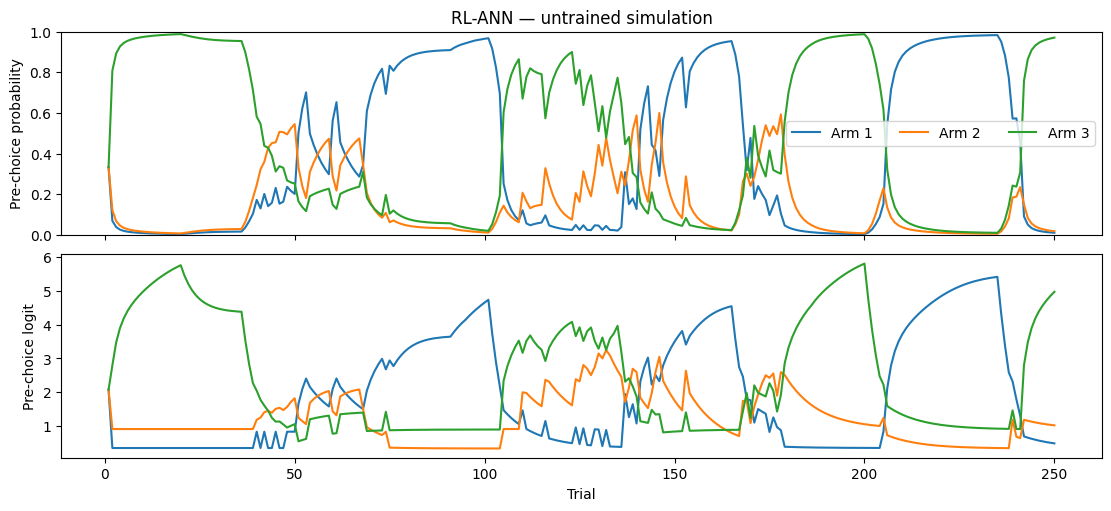

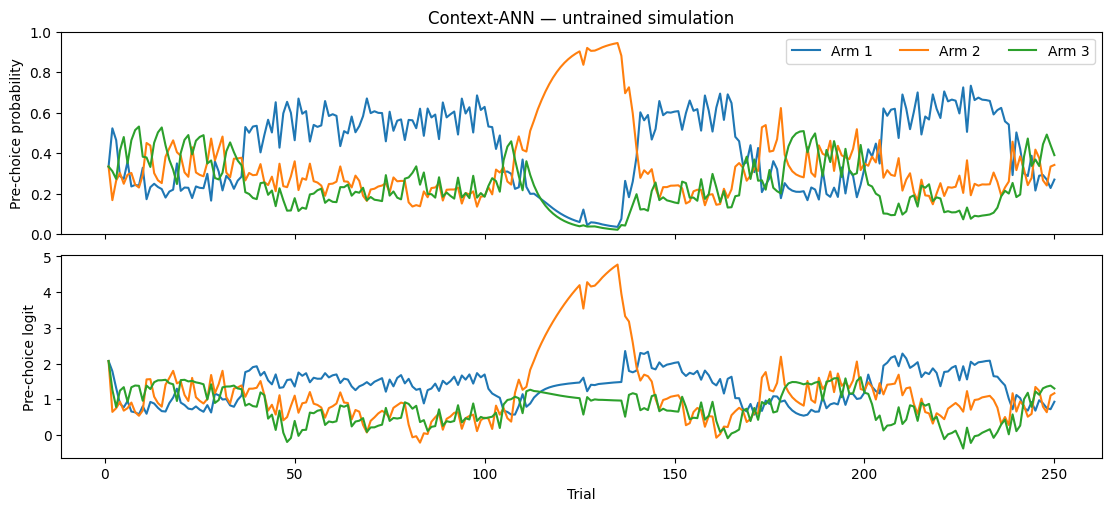

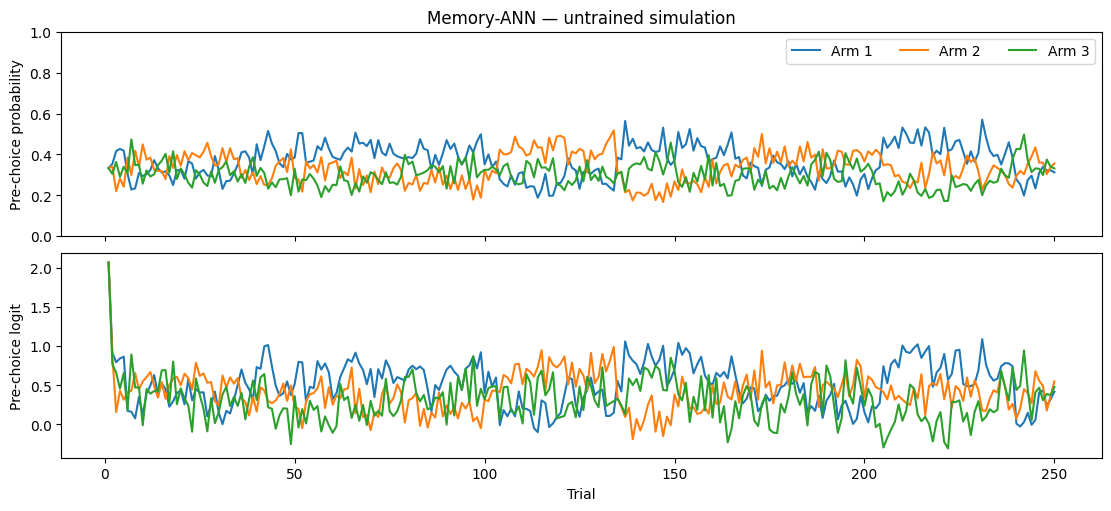

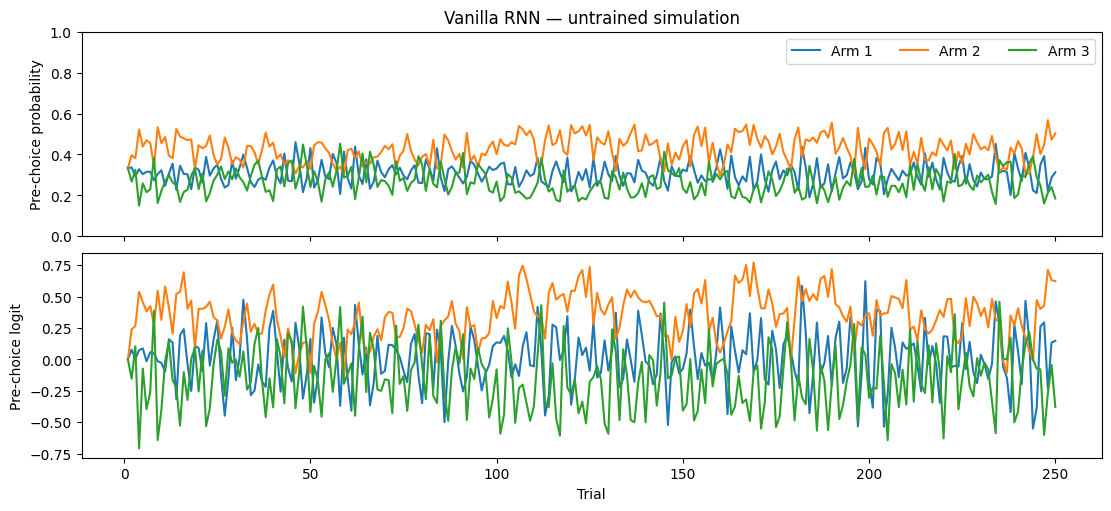

In [11]:
rnn_demo_sessions, rnn_demo_parameters = {}, {}
for model in NEURAL_MODELS:
    params = initialize_parameters(jax.random.PRNGKey(42), model, PAPER_CHOSEN[model]["hidden_units"])
    agent = NeuralBanditMouse(params, model, seed=42)
    numpy_state, python_state = np.random.get_state(), random.getstate()
    try:
        np.random.seed(42)
        random.seed(42)
        task = DriftingBanditTask([0, 1, 4], drift_rate=.1, swap_mode="most_chosen")
        sim_actions, sim_rewards, sim_values = task.simulate(agent, 250)
    finally:
        np.random.set_state(numpy_state)
        random.setstate(python_state)
    seq = dict(mouse="demo", problem=0, session=model, towers=[0, 1, 2],
               actions=np.asarray(sim_actions), rewards=np.asarray(sim_rewards, dtype=float))
    rnn_demo_parameters[model] = params
    rnn_demo_sessions[model] = seq
    trace = trace_sequence(params, seq, model)
    fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, layout="constrained")
    for arm in range(3):
        axes[0].plot(np.arange(1, 251), np.exp(trace["log_probabilities"][:, arm]), label=f"Arm {arm+1}")
        axes[1].plot(np.arange(1, 251), trace["logits"][:, arm], label=f"Arm {arm+1}")
    axes[0].set(title=f"{DISPLAY_NAMES[model]} — untrained simulation", ylabel="Pre-choice probability", ylim=(0, 1))
    axes[1].set(xlabel="Trial", ylabel="Pre-choice logit")
    axes[0].legend(ncol=3)
    plt.show()


## Optional synthetic training check

This is a small behavioral-cloning example, independent of the external data drive. Generate sessions from the existing Q-learning model for ten synthetic subjects, then fit all four neural architectures on an 80/10/10 subject split. Training and evaluation use observed histories, not simulated neural choices. A short run checks execution; it does not establish parameter recovery, data sufficiency, or a scientific architecture ranking. Network flexibility can make short-run validation selection favor initialization.


In [12]:
rnn_run_synthetic = True
if rnn_run_synthetic:
    synthetic_sequences = []
    numpy_state, python_state = np.random.get_state(), random.getstate()
    try:
        for subject in range(10):
            for session in range(2):
                seed = 1000+10*subject+session
                np.random.seed(seed)
                random.seed(seed)
                task = DriftingBanditTask([0, 1, 4], swap_mode="most_chosen")
                generator = QLearningMouse(3, .2, 2., .25)
                a, r, _ = task.simulate(generator, 100)
                synthetic_sequences.append(dict(mouse=f"synthetic-{subject}", problem=session,
                    session=f"ses-{session}", towers=[0, 1, 2], actions=np.asarray(a), rewards=np.asarray(r, dtype=float)))
    finally:
        np.random.set_state(numpy_state)
        random.setstate(python_state)
    rnn_synthetic_results = run_paper_sweep(
        synthetic_sequences, rnn_repo_root / "results/neural_bandit_synthetic",
        models=NEURAL_MODELS,
        grid=[dict(hidden_units=8, optimizer_learning_rate=1e-3, weight_decay=1e-5, batch_size=4)],
        n_seeds=1, max_steps=200, validation_every=50, profile="synthetic-smoke",
    )
    display(pd.DataFrame(rnn_synthetic_results["selected"]))
else:
    print("Set rnn_run_synthetic=True to run the standalone synthetic training example.")


,model,setting,repeat,selected_step,parameters,parameters_file,validation_cross_entropy,validation_release_score,test_cross_entropy,test_release_score,effective_batch_size,geometric_mean_choice_probability
0,rl_ann,"{'hidden_units': 8, 'optimizer_learning_rate':...",0,200,"{'hidden_units': 8, 'n_parameters': 95, 'forge...",rl_ann_selected_parameters.npz,0.540233,0.538724,0.317307,0.316251,4,0.728108
1,context_ann,"{'hidden_units': 8, 'optimizer_learning_rate':...",0,200,"{'hidden_units': 8, 'n_parameters': 143, 'forg...",context_ann_selected_parameters.npz,0.531432,0.530040,0.327793,0.326667,4,0.720512
2,memory_ann,"{'hidden_units': 8, 'optimizer_learning_rate':...",0,200,"{'hidden_units': 8, 'n_parameters': 223, 'forg...",memory_ann_selected_parameters.npz,0.550546,0.549095,0.345715,0.344653,4,0.707714
3,vanilla_rnn,"{'hidden_units': 8, 'optimizer_learning_rate':...",0,200,"{'hidden_units': 8, 'n_parameters': 131}",vanilla_rnn_selected_parameters.npz,0.588778,0.587641,0.421399,0.420474,4,0.656128


## Cohort data: same histories and auditing as the RL notebook

The next setup/loading cells are independent of the RL notebook's kernel. They use its existing cohort-1 pipeline and ordinal problems 5–11, exclude magnitude/pretraining tasks, audit and exclude whole sessions with missing/invalid histories, retain zero rewards, and map physical tower identities to zero-based indices. Configure/mount `cohort_data_root` before loading. Population fits use all usable available sessions; they do not require every mouse to have all seven problems. This includes MY_71_N's available problems 5–10.

If `cohort_sequences` is already loaded in this kernel with these conventions, skip the loading cells. Both notebooks use split seed 42, so **the identical sequence dataset** gives identical training/validation/test mice. A different inclusion audit or sequence dataset may change split membership; compare the saved split identities and data hash, not just the seed.


In [13]:
# Independent cohort setup: no need to run the synthetic neural example first.
import importlib
import json
import sys
from pathlib import Path
from unittest.mock import patch

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cohort_repo_root = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / "src/behavior_import").is_dir()), None
)
if cohort_repo_root is None:
    raise RuntimeError("Run this notebook from within the repository.")
if str(cohort_repo_root) not in sys.path:
    sys.path.insert(0, str(cohort_repo_root))

from src.agents.cohort_fitting import (
    prepare_cohort_sequences,
)
from src.behavior_import.extract_trials import extract_trials_grouped_by_problem
from src.settings import get_settings
cohort_import = importlib.import_module("src.behavior_import.import_data")

# Match the existing cohort-1 analysis notebook. Mount the drive or edit this path.
cohort_data_root = (get_settings().data_root / "3x3_field_magnitude_bandit/rawdata/cohort-01")
cohort_problem_numbers = list(range(5, 12))
cohort_excluded_task_parts = ("mag", "pretraining")
cohort_fit_bounds = [(0.001, 1.0), (0.01, 10.0), (0.0, 3.0)]
cohort_fit_starts = 10
cohort_fit_seed = 42
cohort_output_root = cohort_repo_root / "results/cohort_01_parameter_fitting"
# Explicit exception: six folds for this mouse; seven for all others.
cohort_problem_overrides = {"MY_71_N": list(range(5, 11))}


In [14]:
# Load all eligible sessions first: filtering to later sessions beforehand
# would change the pipeline's ordinal problem numbering.
if not cohort_data_root.is_dir():
    raise FileNotFoundError(
        f"Cohort 1 data not found: {cohort_data_root}. "
        "Mount the data drive or set cohort_data_root to the full cohort directory."
    )
cohort_files = cohort_import.collect_tsv_files(cohort_data_root.resolve())
cohort_eligible_files = []
cohort_file_rows = []
for path, frame in cohort_files:
    task_rows = frame.loc[
        frame["type"].eq("info") & frame["subtype"].eq("task_name"), "content"
    ]
    task_name = str(task_rows.iloc[0]) if len(task_rows) else None
    keep = task_name is not None and not any(
        part in task_name.casefold() for part in cohort_excluded_task_parts
    )
    cohort_file_rows.append({"path": str(path), "task_name": task_name, "included": keep})
    if keep:
        cohort_eligible_files.append((path, frame))
cohort_file_audit = pd.DataFrame(cohort_file_rows, columns=["path", "task_name", "included"])
display(cohort_file_audit.groupby(["task_name", "included"], dropna=False).size().rename("files"))
if not cohort_eligible_files:
    raise ValueError("No eligible task files remain; check the root and the task-name audit.")
with patch.object(cohort_import, "collect_tsv_files", return_value=cohort_eligible_files):
    cohort_raw = cohort_import.import_data(cohort_data_root)
cohort_all_problems = extract_trials_grouped_by_problem(cohort_raw, merge_recurring_problems=False)
print("Available pipeline problem numbers:", sorted(cohort_all_problems))
missing_problems = sorted(set(cohort_problem_numbers) - set(cohort_all_problems))
if missing_problems:
    raise ValueError(
        f"Missing requested pipeline problems: {missing_problems}. "
        "Check the complete cohort data and task filtering; problem numbers will not be relabelled."
    )
cohort_sequences, cohort_session_audit = prepare_cohort_sequences(
    cohort_all_problems, cohort_problem_numbers
)
display(cohort_session_audit.groupby(["mouse", "problem", "included"]).agg(
    sessions=("session", "size"), trials=("n_trials", "sum")
))
display(cohort_session_audit.loc[~cohort_session_audit.included])

[WARN] Failed to read /Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-01_id-MY_71_N/ses-08_date-20260204/behav/._MY_71_N-2026-02-04-153602.tsv: 'utf-8' codec can't decode byte 0xb0 in position 37: invalid start byte.
[WARN] Failed to read /Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-05_id-MY_72_L/ses-155_date-20260613/behav/._MY_72_L-2026-06-13-201430.tsv: 'utf-8' codec can't decode byte 0xb0 in position 37: invalid start byte.
[WARN] Failed to read /Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-02_id-MY_71_L/ses-54_date-20260305/behav/._MY_71_L-2026-03-05-150416.tsv: 'utf-8' codec can't decode byte 0xb0 in position 37: invalid start byte.
[WARN] Failed to read /Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-04_id-MY_72_N/ses-40_date-20260225/behav/._MY_72_N-2026-02-25-143929.tsv: 'utf-8' codec can't decode byte 0xb0 in position 37: invalid start byte.
[WARN] Failed to read /Volumes/behrens/meg/

task_name                                              included
Meg\3x3_field_blocked_reward_bandit_with_cue           True        316
Meg\3x3_field_drifting_value_bandit                    True        467
Meg\3x3_field_drifting_value_bandit_for_recording_71R  True        126
Meg\3x3_field_drifting_value_bandit_for_recording_72L  True         83
Name: files, dtype: int64

/Users/megyoung/magnitude-bandit-analysis/src/behavior_import/import_data.py:226: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[col] = norm[col]
/Users/megyoung/magnitude-bandit-analysis/src/behavior_import/import_data.py:226: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[col] = norm[col]
/Users/megyoung/magnitude-bandit-analysis/src/behavior_import/import_data.py:226: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider 

[INFO] Processed 6 subjects(s), 882 session(s).
[INFO] Split MY_71_R ses-213_date-20260725 into 2 recording segments because the tower configuration changed.
[WARNING] No trial information found for subject MY_71_N, session ses-1_date-20260201
[WARNING] No trial information found for subject MY_71_N, session ses-2_date-20260201
[INFO] Merging multiple files for subject MY_71_N, session ses-8_date-20260204
[INFO] Merging multiple files for subject MY_71_N, session ses-9_date-20260205
[INFO] Merging multiple files for subject MY_71_N, session ses-12_date-20260206
[WARNING] No trial information found for subject MY_71_N, session ses-73_date-20260319
[WARNING] No trial information found for subject MY_71_N, session ses-94_date-20260331
[WARNING] No trial information found for subject MY_72_N, session ses-1_date-20260201
[WARNING] No trial information found for subject MY_72_N, session ses-2_date-20260201
[WARNING] No trial information found for subject MY_72_N, session ses-3_date-20260202


sessions  trials
mouse   problem included                  
MY_71_L 5       True             8     462
        6       True             7     436
        7       True             9     503
        8       True             8     442
        9       True             7     326
        10      True             8     519
        11      True             6     413
MY_71_N 5       True             8     518
        6       True             8     500
        7       True             7     382
        8       True             7     357
        9       True             6     387
        10      True             5     315
MY_71_R 5       True             7     475
        6       True             7     456
        7       True             8     480
        8       True             7     427
        9       True             6     318
        10      True             8     537
        11      True             6     421
MY_72_L 5       True             8     429
        6       True             6     458
        7       True            10     551
        8       True             8     414
        9       True             9     367
        10      True             6     419
        11      True             8     512
MY_72_N 5       True             9     381
        6       True             6     416
        7       True             7     476
        8       True             8     441
        9       True             8     361
        10      True             7     445
        11      True             8     463
MY_72_R 5       True            10     562
        6       True             8     523
        7       True             8     537
        8       True             8     484
        9       True             7     393
        10      True             8     658
        11      True             8     615

,mouse,problem,session,n_trials,included,reason,reward_min,reward_max,towers


## Released-code population fitting for all four architectures

## Training: paper, repository and mouse adaptation

| Detail | Released code | Notebook choice |
|---|---|---|
| Optimizer | `optax.adamw`, decoupled weight decay | Same; no squared-parameter penalty is added to likelihood |
| Sampling | Without replacement within each minibatch | Same; cap requested batch size at available training sessions and record the effective size |
| Inputs/targets | Feed observation t, predict choice t+1 | Same timing; score choices 2…T; first observation still updates state |
| Batch reduction | Sum over trials; divide by number of sampled sessions | Same; variable session lengths use padding masked out of loss and state updates |
| Probability adjustment | `p_adjusted=(1-1e-5)*p+5e-4` | Same training/selection score; also report proper unadjusted likelihood metrics |
| Data split | Utility slices first 10% blocks into train, next 10% validation, remaining 80% test; no subject split | Retain the **paper's** subject-disjoint 80/10/10 design, with mice as subjects and audited integer rounding for pilot/full; local uses whole-problem folds |
| Monitoring | Every 500 loop iterations, sampled validation and test batches | Full validation at configured checkpoints (full profile: 500 updates); test withheld until selection completes |
| Sweep/selection | Public demo trains one configuration and returns last weights | Notebook implements the paper's grid, five seeds and validation-based checkpoint/configuration selection |

The paper describes Adam, summed NLL and sampling with replacement; the release concretely uses AdamW, session-mean loss and sampling without replacement. These disagreements are not silently treated as equivalent. The code's probability adjustment is **not a normalized categorical distribution**: its sum is `1-1e-5+K*5e-4`. It is retained as a released loss proxy. `cross_entropy`, NLL, argmax accuracy and geometric mean choice probability use the proper softmax; `release_nll`, `release_score_per_trial`, and selected-fit `*_release_score` name the adjusted proxy. Validation selection minimizes the proxy per scored trial; on a fixed validation dataset this ranks candidates identically to mean session summed proxy. `n_trials` in population reports is T−1; `n_observed_trials` retains T. Existing L-BFGS-B reports still include all T choices and use proper NLL; their scores must not be directly mixed with these population scores.

The exact released split/monitoring utility is retained for audit/reference tests but is not used for mouse data. We do not copy its hard-coded four-arm target slice: the models and targets use the task's actual arm count. Rewards remain delivered pulses; the released formatter does not rescale rewards. Whole extracted sessions serve as blocks, with no arbitrary 150-trial chopping. The notebooks continue to retain/exclude sessions according to the existing data audit.


### Sweep and execution

Choose `rnn_profile` in the next settings cell:

| Mode | Hidden units | Learning rates | Seeds per setting | Updates per run | Total runs | Total updates |
|---|---|---|---|---|---|---|
| `pilot` | 8 | 1e-3 | 1 | 200 | 4 | 800 |
| `local` (default) | 16 | 1e-3, 1e-4 | 2 | 20,000 | 16 | 320,000 |
| `full` | 16, 32, 64 | 1e-3, 1e-4, 1e-5 | 5 | 1,000,000 | 1,620 | 1,620,000,000 |

The local mode uses weight decay 1e-4 and a batch of 16 sessions, with validation every 500 updates. It provides a preliminary comparison of all four architectures on a modest budget; inspect validation curves to assess whether training has plateaued. Local mode uses **pooled leave-one-problem-out cross-validation**. For each test problem index, that index is held out across all mice; the next available index cyclically is validation; all remaining indices are pooled for training. This fixed validation rule uses no behavioral outcomes. Whole sessions stay together, with state reset per session. Every validation/test mouse must have training sessions, so the question is generalization to unseen problems in familiar mice. Problem indices refer to each mouse's problem order and do not imply identical task configurations across mice. Pilot/full retain the mouse-disjoint split.

The table lists the local budget **per fold**. With problems 5–11, seven folds require 112 fits and 2,240,000 updates. `rnn_test_problems=None` runs all available folds; `[5]` runs only test problem 5 as a preliminary check. `rnn_max_new_runs` limits newly completed fits across all folds. Each fold independently selects its configuration, seed and checkpoint on its validation problem; test outcomes never select models. Final tables aggregate out-of-fold test predictions once per session, and are withheld until all requested folds complete. Do not tune budgets or hyperparameters using these test scores. The fold audit displays exact problem/mouse membership before training. Changing modes creates a separate experiment directory and preserves existing checkpoints. Run the settings cell, fitting cell, then reporting cells; fitting clears the previous result variable to avoid stale reports after interruption.

The full grid is optimizer learning rates [1e-3,1e-4,1e-5] × weight decays [1e-3,1e-4,1e-5] × session batch sizes [32,64,128] × hidden widths [16,32,64], with five seeds per setting and up to 1M updates each: **1,620 runs** across four architectures. The paper's chosen settings are printed above, but winners here are selected on validation mice. For both hybrid channels use the same width. The full profile validates every 500 updates; the pilot checks execution on a much smaller budget.

The runner saves all parameters, AdamW moments, sampler state and validation histories. It resumes the same configuration/source/version and refuses to treat old implementation checkpoints as new models by using manifest-specific directories. Full-validation selection includes step zero; test mice are evaluated only after all requested runs finish. The public demo itself does not implement this complete sweep/selection machinery.

Use the RL notebook's new population section for matched comparisons with RL. The model definitions, loss convention, upstream revision and dataset/split hashes must agree; a seed alone does not establish a fair comparison. Original per-mouse L-BFGS-B fits answer a different generalization question and score the first trial too.


In [15]:
rnn_profile = "local"  # Choose "pilot", "local", or "full".
if rnn_profile == "pilot":
    rnn_fit_settings = dict(
        grid=[dict(hidden_units=8, optimizer_learning_rate=1e-3, weight_decay=1e-5, batch_size=4)],
        n_seeds=1, max_steps=200, validation_every=50,
    )
elif rnn_profile == "local":
    rnn_fit_settings = dict(
        grid=[dict(hidden_units=16, optimizer_learning_rate=lr,
                   weight_decay=1e-4, batch_size=16)
              for lr in [1e-3, 1e-4]],
        n_seeds=2, max_steps=20_000, validation_every=500,
    )
elif rnn_profile == "full":
    rnn_fit_settings = dict(
        grid=[dict(setting, hidden_units=width) for width in [16, 32, 64] for setting in FULL_GRID],
        n_seeds=5, max_steps=1_000_000, validation_every=500,
    )
else:
    raise ValueError("Choose pilot, local, or full.")
# Local mode pools mice and holds out whole problem indices.
# None runs every available problem; use e.g. [5] for one preliminary fold.
rnn_test_problems = [10]
rnn_fold_problems = (sorted({int(s["problem"]) for s in cohort_sequences})
                     if rnn_test_problems is None else list(rnn_test_problems)) if rnn_profile == "local" else []
rnn_n_folds = len(rnn_fold_problems) if rnn_profile == "local" else 1
rnn_total_runs = rnn_n_folds* len(NEURAL_MODELS)*len(rnn_fit_settings["grid"])*rnn_fit_settings["n_seeds"]
print(f"{rnn_profile.upper()}: {rnn_n_folds} fold(s), {rnn_total_runs:,} runs; "
      f"{rnn_total_runs*rnn_fit_settings['max_steps']:,} optimizer updates")


LOCAL: 1 fold(s), 16 runs; 320,000 optimizer updates


In [16]:
# Audit the actual training/validation/test partitions before fitting.
if "cohort_sequences" not in globals():
    raise RuntimeError("Run the cohort setup/loading cells first.")
rnn_audit_rows = []
for test_problem in (rnn_fold_problems if rnn_profile == "local" else [None]):
    if test_problem is None:
        rnn_parts, _ = split_by_mouse(cohort_sequences, seed=42)
    else:
        rnn_parts, _ = split_by_problem(cohort_sequences, test_problem)
    for part, data in rnn_parts.items():
        mice = sorted({s["mouse"] for s in data})
        rnn_audit_rows.append(dict(test_problem=test_problem, partition=part,
            problems=sorted({int(s["problem"]) for s in data}), mice=", ".join(mice),
            n_mice=len(mice), n_sessions=len(data),
            n_trials=sum(len(s["actions"]) for s in data)))
rnn_split_audit = pd.DataFrame(rnn_audit_rows)
display(rnn_split_audit)


,test_problem,partition,problems,mice,n_mice,n_sessions,n_trials
0,10,train,"[5, 6, 7, 8, 9]","MY_71_L, MY_71_N, MY_71_R, MY_72_L, MY_72_N, M...",6,230,13262
1,10,validation,[11],"MY_71_L, MY_71_R, MY_72_L, MY_72_N, MY_72_R",5,36,2424
2,10,test,[10],"MY_71_L, MY_71_N, MY_71_R, MY_72_L, MY_72_N, M...",6,42,2893


In [17]:
# Explicit opt-in; re-execution resumes the same experiment.
rnn_run = True
rnn_max_new_runs = None  # Small integer limits newly completed runs; None finishes all.
# Clear previous results so an interrupted fit cannot display stale comparisons.
globals().pop("rnn_results", None)
if rnn_run:
    rnn_runner = run_problem_sweep if rnn_profile == "local" else run_paper_sweep
    rnn_split_kwargs = dict(test_problems=rnn_fold_problems) if rnn_profile == "local" else {}
    rnn_results = rnn_runner(
        cohort_sequences, rnn_repo_root / "results/paper_style_neural_fitting",
        models=NEURAL_MODELS, **rnn_fit_settings, **rnn_split_kwargs,
        split_seed=42, fit_seed=123, max_new_runs=rnn_max_new_runs, profile=rnn_profile,
    )
    print("COMPLETE" if rnn_results["complete"] else "PARTIAL",
          f"{rnn_results['completed_runs']}/{rnn_results['expected_runs']} runs", rnn_results["output_dir"])
    display(pd.DataFrame(rnn_results["selected"]))
else:
    print("Set rnn_run=True to run/resume the selected fitting profile.")


Pooled problem fold: test problem 10
COMPLETE 16/16 runs /Users/megyoung/magnitude-bandit-analysis/results/paper_style_neural_fitting/problem-cv-d1a7b2be37b2


,model,setting,repeat,selected_step,parameters,parameters_file,validation_cross_entropy,validation_release_score,test_cross_entropy,test_release_score,effective_batch_size,geometric_mean_choice_probability,test_problem
0,rl_ann,"{'hidden_units': 16, 'optimizer_learning_rate'...",0,10500,"{'hidden_units': 16, 'n_parameters': 183, 'for...",/Users/megyoung/magnitude-bandit-analysis/resu...,0.582767,0.581418,0.728132,0.726569,16,0.482810,10
1,context_ann,"{'hidden_units': 16, 'optimizer_learning_rate'...",0,10500,"{'hidden_units': 16, 'n_parameters': 279, 'for...",/Users/megyoung/magnitude-bandit-analysis/resu...,0.584273,0.582936,0.732882,0.731302,16,0.480522,10
2,memory_ann,"{'hidden_units': 16, 'optimizer_learning_rate'...",0,2500,"{'hidden_units': 16, 'n_parameters': 695, 'for...",/Users/megyoung/magnitude-bandit-analysis/resu...,0.594141,0.592829,0.723263,0.721763,16,0.485166,10
3,vanilla_rnn,"{'hidden_units': 16, 'optimizer_learning_rate'...",0,3500,"{'hidden_units': 16, 'n_parameters': 387}",/Users/megyoung/magnitude-bandit-analysis/resu...,0.588028,0.586715,0.735994,0.734403,16,0.479029,10


## Held-out metrics and model comparisons

Population metrics now score choices **2…T**, matching released input/target alignment. `n_trials` is the number scored; `n_observed_trials` includes the initial observation. The proper softmax NLL, cross entropy, geometric mean assigned probability and argmax accuracy are reported separately from the affine-adjusted released loss (`release_nll`, `release_score_per_trial`). The adjusted values do not sum to a normalized categorical distribution and are not labelled proper likelihoods.

Lower proper cross entropy is better; its uniform baseline is log(3). exp(−CE) is geometric mean assigned probability, not percentage correct. Argmax accuracy is separately reported, with ties taking the lowest indexed arm. Pooling NLL/trials weights trials; the mouse-level table supports equal-mouse averages. All architectures use the same held-out sessions (mice for pilot/full, problems for local); repeated sessions or seeds are not independent subjects. A small mouse count limits scientific conclusions. In local mode these are pooled out-of-fold predictions, with each session scored only in its own test fold. The selected-parameter table has one winner per architecture per fold, not one overall fitted network.


In [18]:
if rnn_run and "rnn_results" in globals() and rnn_results["complete"]:
    rnn_output = Path(rnn_results["output_dir"])
    rnn_test_sessions = pd.DataFrame(rnn_results["test_sessions"])
    rnn_test_sessions.to_csv(rnn_output / "test_sessions.csv", index=False)
    display(rnn_test_sessions)
    rnn_mouse_scores = rnn_test_sessions.groupby(["model", "mouse"]).agg(
        n_sessions=("session", "size"), n_trials=("n_trials", "sum"), nll=("nll", "sum"))
    rnn_mouse_scores["cross_entropy"] = rnn_mouse_scores.nll/rnn_mouse_scores.n_trials
    rnn_mouse_scores["geometric_mean_choice_probability"] = np.exp(-rnn_mouse_scores.cross_entropy)
    rnn_paired_scores = rnn_mouse_scores.cross_entropy.unstack("model")
    rnn_paired_scores["memory_improvement_over_vanilla"] = rnn_paired_scores.vanilla_rnn-rnn_paired_scores.memory_ann
    display(rnn_mouse_scores)
    display(rnn_paired_scores)
    print("Equal-mouse mean CE:", rnn_mouse_scores.cross_entropy.groupby("model").mean().to_dict())
    rnn_mouse_scores.to_csv(rnn_output / "test_mouse_scores.csv")
    rnn_paired_scores.to_csv(rnn_output / "test_paired_model_scores.csv")
else:
    print("No complete sweep from this run; held-out test comparisons are withheld.")


,model,mouse,problem,session,n_trials,n_observed_trials,nll,cross_entropy,release_nll,release_score_per_trial,geometric_mean_choice_probability,argmax_accuracy,test_problem
0,rl_ann,MY_71_L,10,ses-86_date-20260325,8,9,5.891537,0.736442,5.882435,0.735304,0.478814,0.625000,10
1,rl_ann,MY_71_L,10,ses-87_date-20260326,68,69,42.988234,0.632180,42.893586,0.630788,0.531432,0.794118,10
2,rl_ann,MY_71_L,10,ses-88_date-20260326,50,51,44.352058,0.887041,44.263589,0.885272,0.411873,0.600000,10
3,rl_ann,MY_71_L,10,ses-89_date-20260327,67,68,56.308393,0.840424,56.206566,0.838904,0.431528,0.626866,10
4,rl_ann,MY_71_L,10,ses-90_date-20260327,26,27,20.492468,0.788172,20.461261,0.786972,0.454675,0.615385,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,vanilla_rnn,MY_72_R,10,ses-87_date-20260326,51,52,46.483101,0.911433,46.374225,0.909299,0.401948,0.607843,10
164,vanilla_rnn,MY_72_R,10,ses-88_date-20260326,108,109,68.151600,0.631033,68.011290,0.629734,0.532042,0.722222,10
165,vanilla_rnn,MY_72_R,10,ses-89_date-20260327,109,110,69.375175,0.636469,69.207985,0.634936,0.529157,0.752294,10
166,vanilla_rnn,MY_72_R,10,ses-90_date-20260327,77,78,53.434483,0.693954,53.304920,0.692272,0.499597,0.714286,10


n_sessions  n_trials         nll  cross_entropy  \
model       mouse                                                      
context_ann MY_71_L           8       511  350.602646       0.686111   
            MY_71_N           5       310  231.551657       0.746941   
            MY_71_R           8       529  432.043519       0.816717   
            MY_72_L           6       413  312.781987       0.757341   
            MY_72_N           7       438  297.113882       0.678342   
            MY_72_R           8       650  465.353965       0.715929   
memory_ann  MY_71_L           8       511  338.737345       0.662891   
            MY_71_N           5       310  228.653979       0.737593   
            MY_71_R           8       529  430.262814       0.813351   
            MY_72_L           6       413  304.044988       0.736186   
            MY_72_N           7       438  293.483461       0.670054   
            MY_72_R           8       650  466.840847       0.718217   
rl_ann      MY_71_L           8       511  347.066915       0.679192   
            MY_71_N           5       310  228.358825       0.736641   
            MY_71_R           8       529  427.779339       0.808657   
            MY_72_L           6       413  313.012865       0.757900   
            MY_72_N           7       438  297.768238       0.679836   
            MY_72_R           8       650  461.917520       0.710642   
vanilla_rnn MY_71_L           8       511  345.939434       0.676985   
            MY_71_N           5       310  233.772807       0.754106   
            MY_71_R           8       529  431.881699       0.816412   
            MY_72_L           6       413  310.655989       0.752194   
            MY_72_N           7       438  299.915068       0.684738   
            MY_72_R           8       650  476.154734       0.732546   

                     geometric_mean_choice_probability  
model       mouse                                       
context_ann MY_71_L                           0.503531  
            MY_71_N                           0.473814  
            MY_71_R                           0.441880  
            MY_72_L                           0.468911  
            MY_72_N                           0.507458  
            MY_72_R                           0.488738  
memory_ann  MY_71_L                           0.515359  
            MY_71_N                           0.478263  
            MY_71_R                           0.443370  
            MY_72_L                           0.478937  
            MY_72_N                           0.511681  
            MY_72_R                           0.487621  
rl_ann      MY_71_L                           0.507027  
            MY_71_N                           0.478719  
            MY_71_R                           0.445456  
            MY_72_L                           0.468649  
            MY_72_N                           0.506700  
            MY_72_R                           0.491328  
vanilla_rnn MY_71_L                           0.508147  
            MY_71_N                           0.470431  
            MY_71_R                           0.442015  
            MY_72_L                           0.471331  
            MY_72_N                           0.504223  
            MY_72_R                           0.480684

model,context_ann,memory_ann,rl_ann,vanilla_rnn,memory_improvement_over_vanilla
mouse,,,,,
MY_71_L,0.686111,0.662891,0.679192,0.676985,0.014094
MY_71_N,0.746941,0.737593,0.736641,0.754106,0.016512
MY_71_R,0.816717,0.813351,0.808657,0.816412,0.003060
MY_72_L,0.757341,0.736186,0.757900,0.752194,0.016007
MY_72_N,0.678342,0.670054,0.679836,0.684738,0.014684
MY_72_R,0.715929,0.718217,0.710642,0.732546,0.014329


Equal-mouse mean CE: {'context_ann': 0.7335636425659376, 'memory_ann': 0.7230487475709925, 'rl_ann': 0.7288114128545033, 'vanilla_rnn': 0.7361632623620089}


## Inspect a selected model and its state trajectories

Choose a model and a saved selected-weight file. Loading `.npz` uses `allow_pickle=False`. The trace includes pre-choice logits/probabilities, Q/c and hidden states, plus Q/c after observation. Inspecting test trajectories describes a selected model; using those observations to redesign or tune a model consumes the test set, so a subsequent evaluation needs new held-out data.

Hybrid plots show both Q and c contributions; their sum is the logit. The hidden-state plot shows vector **norms**, not inferred psychological quantities or uniquely identifiable neural dimensions. Vanilla RNN's unused hybrid channels remain zero placeholders in the unified state container and are not plotted/interpreted.


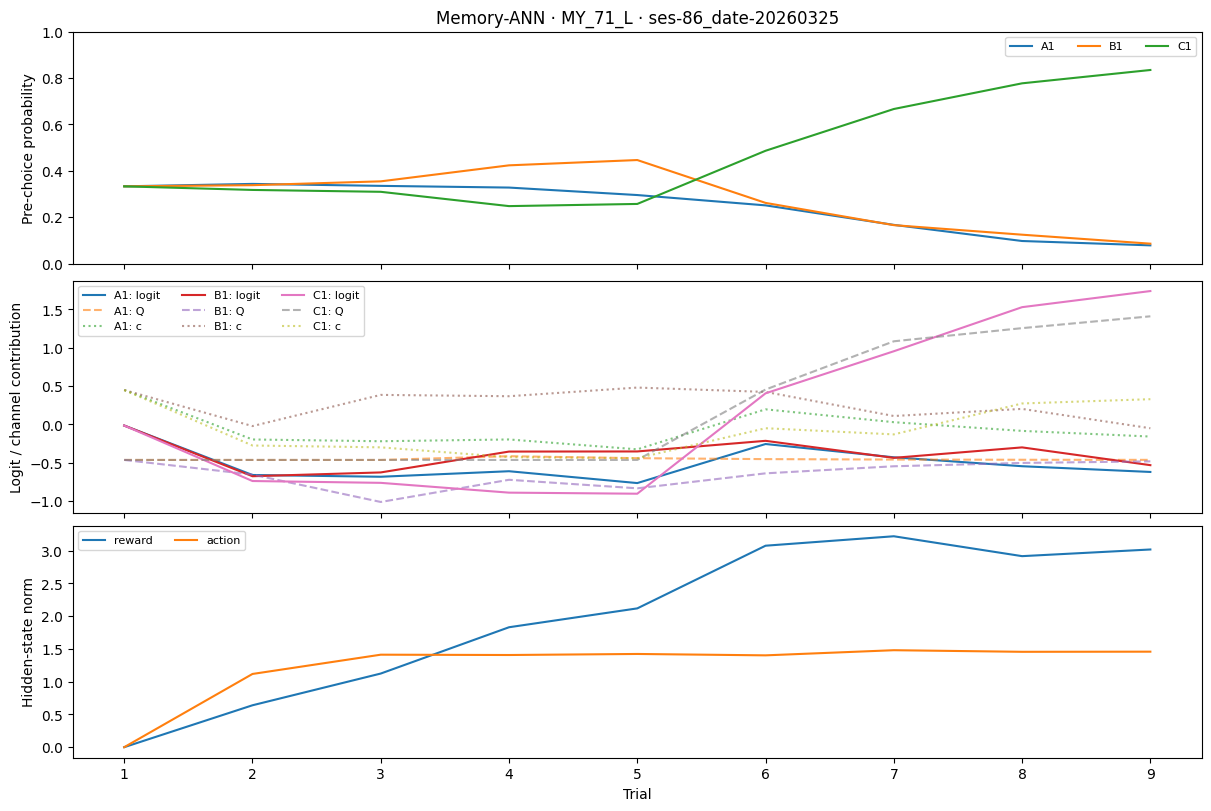

In [19]:
rnn_inspect_model = "memory_ann"
rnn_inspect_problem = None  # None selects the first completed fold; or choose e.g. 5.
if rnn_run and "rnn_results" in globals() and rnn_results["complete"]:
    if rnn_results.get("split_strategy") == "pooled_problem":
        inspection_folds = rnn_results["folds"]
        rnn_inspection_results = (inspection_folds[0] if rnn_inspect_problem is None else
            next(f for f in inspection_folds if f["test_problem"] == rnn_inspect_problem))
    else:
        rnn_inspection_results = rnn_results
    chosen = next(row for row in rnn_inspection_results["selected"] if row["model"] == rnn_inspect_model)
    with np.load(Path(rnn_inspection_results["output_dir"])/chosen["parameters_file"], allow_pickle=False) as saved:
        inspected_parameters = {key: jnp.asarray(saved[key]) for key in saved.files}
    inspect_mouse = rnn_inspection_results["split_mice"]["test"][0]
    inspected_sequence = next(s for s in cohort_sequences if s["mouse"] == inspect_mouse
        and (rnn_inspection_results.get("split_problems") is None or
             int(s["problem"]) in rnn_inspection_results["split_problems"]["test"]))
    inspected_trace = trace_sequence(inspected_parameters, inspected_sequence, rnn_inspect_model)
    n = min(250, len(inspected_sequence["actions"]))
    trials = np.arange(1, n+1)
    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, layout="constrained")
    for arm, tower in enumerate(inspected_sequence["towers"]):
        axes[0].plot(trials, np.exp(inspected_trace["log_probabilities"][:n, arm]), label=tower)
        axes[1].plot(trials, inspected_trace["logits"][:n, arm], label=f"{tower}: logit")
        if rnn_inspect_model != "vanilla_rnn":
            axes[1].plot(trials, inspected_trace["pre_q"][:n, arm], linestyle="--", alpha=.6, label=f"{tower}: Q")
            axes[1].plot(trials, inspected_trace["pre_c"][:n, arm], linestyle=":", alpha=.6, label=f"{tower}: c")
    hidden_channels = ["joint"] if rnn_inspect_model == "vanilla_rnn" else ["reward", "action"]
    for channel in hidden_channels:
        axes[2].plot(trials, np.linalg.norm(inspected_trace[f"pre_{channel}_hidden"][:n], axis=1), label=channel)
    axes[0].set(title=f"{DISPLAY_NAMES[rnn_inspect_model]} · {inspect_mouse} · {inspected_sequence['session']}",
                ylabel="Pre-choice probability", ylim=(0, 1))
    axes[1].set_ylabel("Logit / channel contribution")
    axes[2].set(xlabel="Trial", ylabel="Hidden-state norm")
    for ax in axes:
        ax.legend(ncol=3, fontsize=8)
    plt.show()
else:
    print("Complete a configured sweep before inspecting its selected models.")


## Controlled reward-function probes

For RL-ANN and Context-ANN, probes report **decayed previous chosen Q plus the learned increment**. Context probes update the chosen entry in the context vector consistently. For Memory-ANN they report the replacement output directly, without decaying the chosen value; chosen Q is not an input, while the code's dummy zero slot remains present.

The example uses training rewards/states to choose probe ranges and reference context. Reference states need not be states the network actually visits. Curves describe fitted computations, not proven psychological mechanisms or global monotonicity. Vanilla RNN has no separate reward module. Reusing test diagnostics to redesign models consumes the test set and calls for a fresh held-out evaluation.


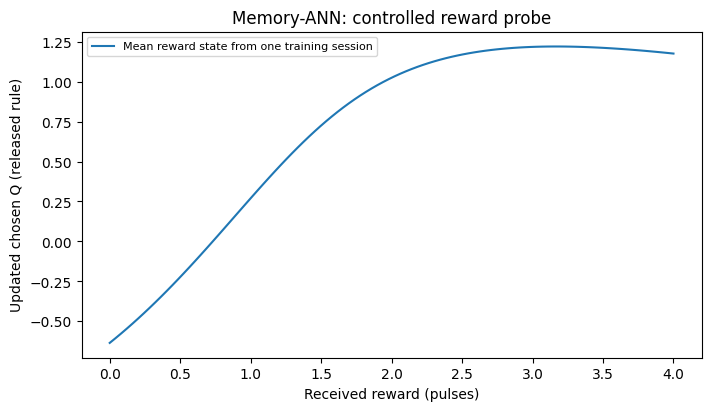

In [20]:
if rnn_run and "rnn_results" in globals() and rnn_results["complete"] and rnn_inspect_model != "vanilla_rnn":
    train_mice = set(rnn_inspection_results["split_mice"]["train"])
    training_sequences = [s for s in cohort_sequences if s["mouse"] in train_mice
        and (rnn_inspection_results.get("split_problems") is None or
             int(s["problem"]) in rnn_inspection_results["split_problems"]["train"])]
    training_rewards = np.concatenate([s["rewards"] for s in training_sequences])
    reference_sequence = training_sequences[0]
    reference_trace = trace_sequence(inspected_parameters, reference_sequence, rnn_inspect_model)
    probe_rewards = np.linspace(training_rewards.min(), training_rewards.max(), 100)
    if rnn_inspect_model == "memory_ann":
        hidden_reference = reference_trace["pre_reward_hidden"].mean(axis=0)
        curves = probe_reward_module(inspected_parameters, rnn_inspect_model, probe_rewards,
                                    reward_hidden=hidden_reference)
        labels = ["Mean reward state from one training session"]
    else:
        chosen_values = np.quantile(reference_trace["pre_q"], [.1, .5, .9])
        curves = probe_reward_module(inspected_parameters, rnn_inspect_model, probe_rewards,
            chosen_values=chosen_values, context=reference_trace["pre_q"].mean(axis=0))
        labels = [f"Chosen Q={v:.3g}" for v in chosen_values]
    fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
    for curve, label in zip(curves, labels):
        ax.plot(probe_rewards, curve, label=label)
    ax.set(xlabel="Received reward (pulses)", ylabel="Updated chosen Q (released rule)",
           title=f"{DISPLAY_NAMES[rnn_inspect_model]}: controlled reward probe")
    ax.legend(fontsize=8)
    plt.show()
else:
    print("Select a fitted hybrid model to inspect its independent reward module.")


## Interactive trajectories across models

Choose a **subject** and **session** to compare all four architectures on the same observed history. The trajectory dropdown switches between choice probabilities, logits, reward-channel Q and action-channel c. Vanilla RNN has no separate Q/c channels. Arm colors refer to the physical towers in that session. Observed actions and delivered rewards appear below the model panels; use the trial-range slider to zoom.

Every prediction is made **before** observing that trial's choice/reward. These are one-step predictions conditioned on actual past behavior, not free-running simulations. Q and c are learned channel contributions, and their numerical scales need not be comparable across architectures.

Only sessions with completed, selected fits for **all four models** are offered. In local mode the viewer uses the session's held-out problem fold; in pilot/full it offers only held-out mice. Subjects may therefore have fewer sessions in the dropdown than in the raw data. Completed folds from a partial problem sweep can be inspected, but their test outcomes must not be used to tune subsequent fits. Changing the selection only replays saved weights and does not train anything.

Run the setup/data-loading cells first. Use `rnn_results` from the fitting cell, or set `rnn_trajectory_results_path` below to an existing experiment's `results.json` to view saved fits without rerunning training. Saved weight files must remain at the locations recorded by those results. The widget requires `ipywidgets` in the notebook kernel (`%pip install ipywidgets` if missing).

The viewer replays weights with NumPy on CPU, avoiding JAX compilation. The plotting replay is checked against the training implementation.


In [ ]:
import importlib
import src.agents.trajectory_viewer as trajectory_viewer_module
importlib.reload(trajectory_viewer_module)  # Pick up viewer fixes without restarting the trained kernel.
trajectory_viewer = trajectory_viewer_module.trajectory_viewer

rnn_trajectory_results_path = None  # Optional: "/absolute/path/to/results.json"
if rnn_trajectory_results_path is not None:
    rnn_trajectory_results = json.loads(Path(rnn_trajectory_results_path).read_text())
else:
    rnn_trajectory_results = globals().get("rnn_results")

if rnn_trajectory_results is None:
    print("Complete fitting or set rnn_trajectory_results_path to saved results.json.")
elif "cohort_sequences" not in globals():
    print("Run the cohort data-loading cells before opening the viewer.")
else:
    rnn_trajectory_widget = trajectory_viewer(rnn_trajectory_results, cohort_sequences)
    display(rnn_trajectory_widget)


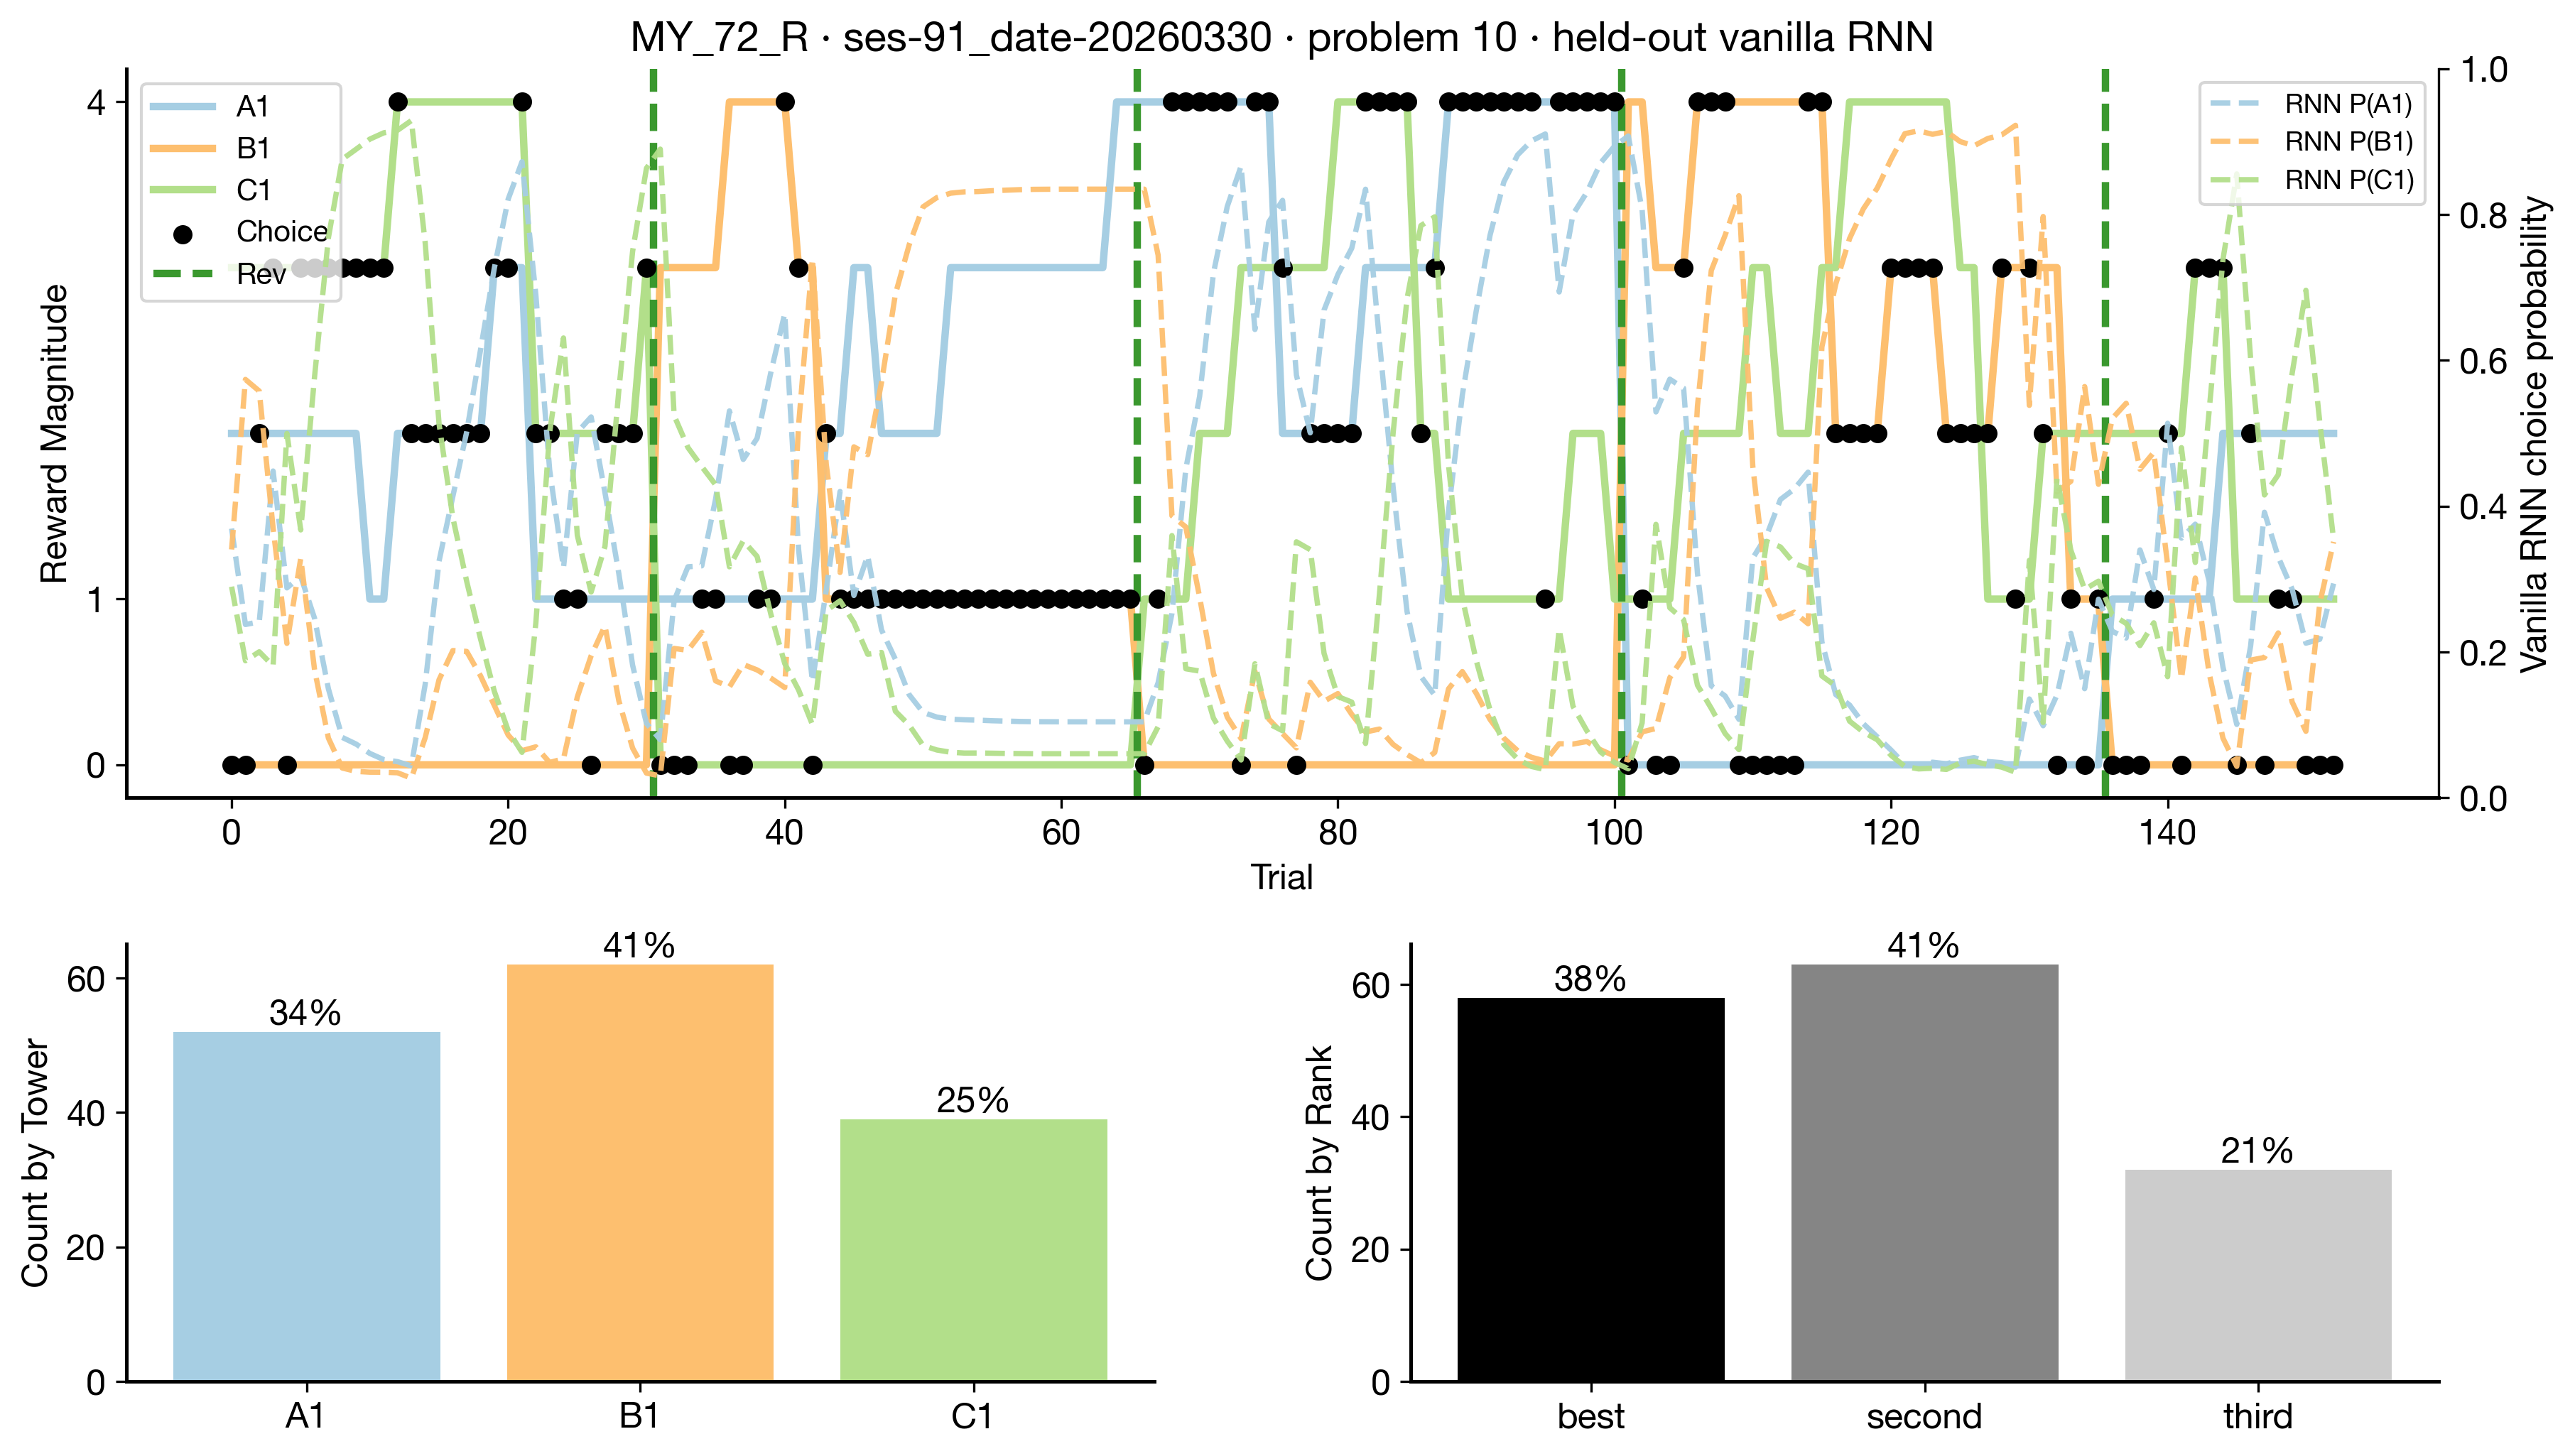

Saved PNG and PDF: /Users/megyoung/magnitude-bandit-analysis/results/paper_style_neural_fitting/1cfbd6f10986/session_overlays/MY_72_R_ses-91_date-20260330_vanilla_rnn
Trial numbering follows the behavior plot (zero-based). Probabilities use only previous choices/rewards.


In [22]:
# Single-session behavior summary with held-out vanilla RNN predictions.
# Solid colored lines: available reward magnitudes; black dots: observed choices.
# Dashed colored lines: pre-choice probabilities (right axis), using the same tower colors.
import re
import importlib
import numpy as np
from pathlib import Path
from IPython.display import Image, display
from src.agents.trajectory_viewer import replay_numpy

example_subject = "MY_72_R"
example_session_number = 91

if "cohort_sequences" not in globals() or "cohort_all_problems" not in globals():
    raise RuntimeError("Run the cohort data-loading cells first.")
example_results = globals().get("rnn_trajectory_results") or globals().get("rnn_results")
if example_results is None:
    raise RuntimeError("Run the fitting cell or load saved results in the trajectory viewer cell first.")
example_matches = [s for s in cohort_sequences if s["mouse"] == example_subject
                   and re.match(rf"^ses-0*{example_session_number}(?:_|$)", s["session"])]
if len(example_matches) != 1:
    raise ValueError(f"Expected one audited session for {example_subject}, session {example_session_number}; "
                     f"found {[s['session'] for s in example_matches]}. "
                     "Check the cohort audit; configuration-split sessions must be selected explicitly.")
example_sequence = example_matches[0]
example_folds = []
for fold in example_results.get("folds", [example_results]):
    problems = fold.get("split_problems")
    if (fold.get("complete") and example_subject in fold["split_mice"]["test"]
            and (problems is None or int(example_sequence["problem"]) in problems["test"])
            and any(row["model"] == "vanilla_rnn" for row in fold["selected"])):
        example_folds.append(fold)
if len(example_folds) != 1:
    raise ValueError("No unique completed held-out vanilla RNN fit for this session. "
                     "Complete its problem fold in local mode (or choose a test mouse for pilot/full).")
example_fold = example_folds[0]
example_selected = next(row for row in example_fold["selected"] if row["model"] == "vanilla_rnn")
with np.load(Path(example_fold["output_dir"])/example_selected["parameters_file"], allow_pickle=False) as saved:
    example_parameters = {key: saved[key] for key in saved.files}
example_trace = replay_numpy(example_parameters, example_sequence, "vanilla_rnn")
example_behavior = cohort_all_problems[example_sequence["problem"]][example_subject][example_sequence["session"]]
example_towers = example_sequence["towers"]
if list(example_behavior["choice"]) != [example_towers[a] for a in example_sequence["actions"]]:
    raise ValueError("Behavior and model choice histories are not aligned.")
np.testing.assert_array_equal(example_behavior["reward_pulses"], example_sequence["rewards"])
example_probabilities = np.exp(example_trace["log_probabilities"])
example_probabilities_by_tower = {tower: example_probabilities[:, arm]
                                  for arm, tower in enumerate(example_towers)}
example_plot_module = importlib.import_module("src.behavior_visualization.plot_single_session")
importlib.reload(example_plot_module)
example_output = Path(example_fold["output_dir"])/"session_overlays"/f"{example_subject}_{example_sequence['session']}_vanilla_rnn"
example_plot_module.plot_single_session(
    example_behavior,
    title=f"{example_subject} · {example_sequence['session']} · problem {example_sequence['problem']} · held-out vanilla RNN",
    save_path=example_output,
    choice_probabilities_by_tower=example_probabilities_by_tower,
)
display(Image(filename=str(example_output)+".png"))
print("Saved PNG and PDF:", example_output)
print("Trial numbering follows the behavior plot (zero-based). Probabilities use only previous choices/rewards.")


In [ ]:
# Single-session behavior summary with held-out vanilla RNN predictions.
# Solid colored lines: available reward magnitudes; black dots: observed choices.
# Dashed colored lines: pre-choice probabilities (right axis), using the same tower colors.
import re
import importlib
import numpy as np
from pathlib import Path
from IPython.display import Image, display
from src.agents.trajectory_viewer import replay_numpy

example_subject = "MY_72_R"
example_session_number = 91

if "cohort_sequences" not in globals() or "cohort_all_problems" not in globals():
    raise RuntimeError("Run the cohort data-loading cells first.")
example_results = globals().get("rnn_trajectory_results") or globals().get("rnn_results")
if example_results is None:
    raise RuntimeError("Run the fitting cell or load saved results in the trajectory viewer cell first.")
example_matches = [s for s in cohort_sequences if s["mouse"] == example_subject
                   and re.match(rf"^ses-0*{example_session_number}(?:_|$)", s["session"])]
if len(example_matches) != 1:
    raise ValueError(f"Expected one audited session for {example_subject}, session {example_session_number}; "
                     f"found {[s['session'] for s in example_matches]}. "
                     "Check the cohort audit; configuration-split sessions must be selected explicitly.")
example_sequence = example_matches[0]
example_folds = []
for fold in example_results.get("folds", [example_results]):
    problems = fold.get("split_problems")
    if (fold.get("complete") and example_subject in fold["split_mice"]["test"]
            and (problems is None or int(example_sequence["problem"]) in problems["test"])
            and any(row["model"] == "vanilla_rnn" for row in fold["selected"])):
        example_folds.append(fold)
if len(example_folds) != 1:
    raise ValueError("No unique completed held-out vanilla RNN fit for this session. "
                     "Complete its problem fold in local mode (or choose a test mouse for pilot/full).")
example_fold = example_folds[0]
example_selected = next(row for row in example_fold["selected"] if row["model"] == "vanilla_rnn")
with np.load(Path(example_fold["output_dir"])/example_selected["parameters_file"], allow_pickle=False) as saved:
    example_parameters = {key: saved[key] for key in saved.files}
example_trace = replay_numpy(example_parameters, example_sequence, "vanilla_rnn")
example_behavior = cohort_all_problems[example_sequence["problem"]][example_subject][example_sequence["session"]]
example_towers = example_sequence["towers"]
if list(example_behavior["choice"]) != [example_towers[a] for a in example_sequence["actions"]]:
    raise ValueError("Behavior and model choice histories are not aligned.")
np.testing.assert_array_equal(example_behavior["reward_pulses"], example_sequence["rewards"])
example_probabilities = np.exp(example_trace["log_probabilities"])
example_probabilities_by_tower = {tower: example_probabilities[:, arm]
                                  for arm, tower in enumerate(example_towers)}
example_plot_module = importlib.import_module("src.behavior_visualization.plot_single_session")
importlib.reload(example_plot_module)
example_output = Path(example_fold["output_dir"])/"session_overlays"/f"{example_subject}_{example_sequence['session']}_vanilla_rnn"
example_plot_module.plot_single_session(
    example_behavior,
    title=f"{example_subject} · {example_sequence['session']} · problem {example_sequence['problem']} · held-out vanilla RNN",
    save_path=example_output,
    choice_probabilities_by_tower=example_probabilities_by_tower,
)
display(Image(filename=str(example_output)+".png"))
print("Saved PNG and PDF:", example_output)
print("Trial numbering follows the behavior plot (zero-based). Probabilities use only previous choices/rewards.")
